In [1]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from skimage.io import imread
# Write yor imports here

# Statistics Exercise
## Statistical Distributions. Properties of distributions. Applications of Probability and Statistics in Computer Science

### Problem 1. Plotting a Single Distribution. Digits in $\pi$ and $e$
We expect that the decimal digits in $\pi$ and $e$ will be randomly distributed and there's no reason for any digit to dominate over others. Let's verify this.

Using an algorithm, the first 10 004 digits of $\pi$ and $e$ were generated:
$$
\pi = 3.(141592 \dots 5678)5667
$$
$$
e = 2.(718281 \dots 6788)5674
$$

The 10 000 digits in brackets were counted. You can see the results in `digits.dat`. Each column corresponds to one digit from 0 to 9. The first row is for $\pi$ and the second row is for $e$.

How are these digits distributed? Are the two distributions different?

**Note:** The dataset is **not properly formatted** to work easily. You can transpose it. Now, digit counts will be in rows and variables - in columns. 
```python
digits = pd.read_table("digits.dat", header = None).T
```

You can also specify column names like this:
```python
digits.columns = ["pi", "e"]
```

Also note that **we are not creating the histogram of the distribution**. We already have the counts, we need to plot them. In a sense, the histogram has already been calculated.

To do this, we can create a "bar chart" (using `plt.bar()`). We have to provide values for the x-axis and y-axis. For the x-axis, we have the numbers 0 through 9 (we can use the *index* of the dataset like this: `digits.index`). For the y-axis, we need to plot the digit counts directly.

We can see that even the simplest datasets sometimes need a bit of preprocessing. This is always the case when we're working with data.

In [3]:
digits = pd.read_table("digits.dat", header=None).T
digits.columns = ["pi", "e"]

digits
# Write your code here

,pi,e
0,968,974
1,1026,989
2,1021,1004
3,974,1008
4,1012,982
5,1046,992
6,1021,1079
7,970,1008
8,948,996
9,1014,968


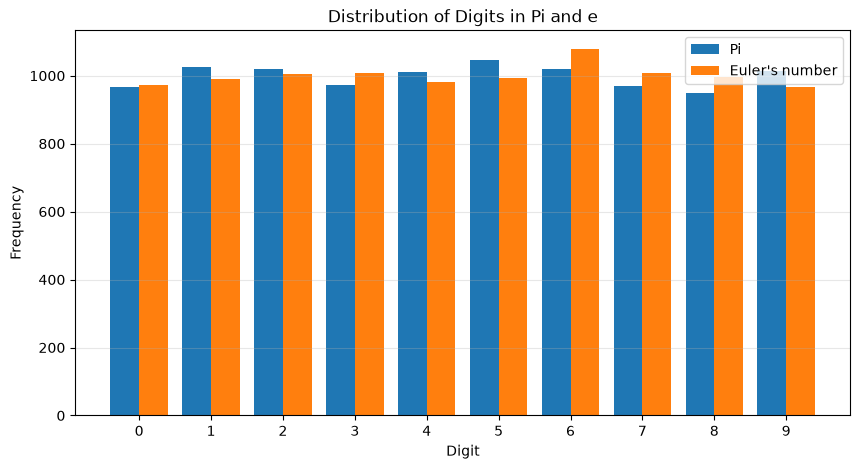

In [4]:
plt.figure(figsize=(10, 5))

plt.bar(digits.index - 0.2, digits["pi"], width=0.4, label="Pi")
plt.bar(digits.index + 0.2, digits["e"], width=0.4, label="Euler's number")

plt.xlabel("Digit")
plt.ylabel("Frequency")
plt.title("Distribution of Digits in Pi and e")
plt.xticks(digits.index)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()
# Write your code here

### Conclusion

The decimal digits of **π** and **e** appear approximately uniformly distributed.

Each digit occurs close to **1,000 times** among the 10,000 examined digits.

The two distributions show small differences, but neither has a strongly dominant digit.

**The observed frequencies are consistent with an approximately uniform distribution.**

Let's try something else. Scientists have measured the percentage of silica ($\text{SiO}_2$, sand / glass) for 22 meteors. You can find it in `silica.dat`. How are these distributed? What is a "typical" percentage? Is there such percentage at all?

Print the mean, standard deviation (you can use the biased or unbiased formula), skewness and kurtosis of the distribution. What do these numbers tell you? How do they relateto the shape of the distribution? Can you characterize the distribution better? (An idea would be to characterize different parts of it on their own, as if they're different distributions.)

In [5]:
# Write your code here
silica = pd.read_table("silica.dat", header=None)

silica

,0
0,20.77
1,22.56
2,22.71
3,22.99
4,26.39
5,27.08
6,27.32
7,27.33
8,27.57
9,27.81


In [6]:
silica_values = silica[0]

print(f"Mean: {silica_values.mean():.4f}")
print(f"Standard deviation: {silica_values.std():.4f}")
print(f"Skewness: {silica_values.skew():.4f}")
print(f"Kurtosis: {silica_values.kurt():.4f}")

Mean: 29.1650
Standard deviation: 4.2915
Skewness: -0.4464
Kurtosis: -0.9243


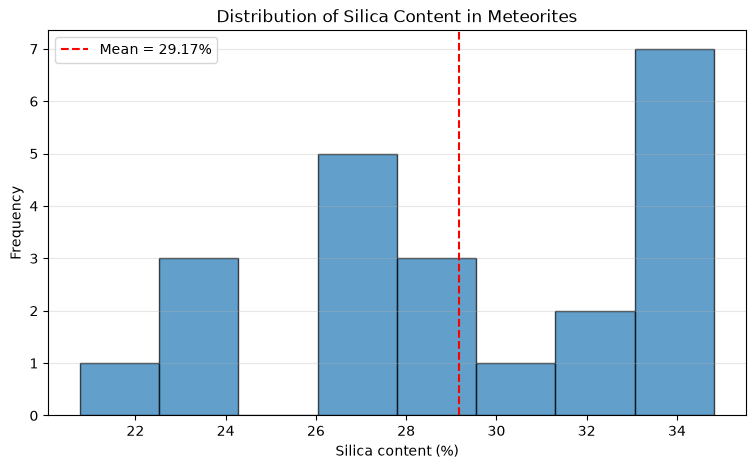

In [7]:
plt.figure(figsize=(9, 5))

plt.hist(silica_values, bins=8, edgecolor="black", alpha=0.7)

plt.axvline(
    silica_values.mean(),
    color="red",
    linestyle="--",
    label=f"Mean = {silica_values.mean():.2f}%"
)

plt.xlabel("Silica content (%)")
plt.ylabel("Frequency")
plt.title("Distribution of Silica Content in Meteorites")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

### Conclusion — Silica Distribution

The silica content in the 22 meteorite samples ranges from
20.77% to 34.82%.

**Statistical results:**
- Mean: 29.1650%
- Standard deviation: 4.2915
- Skewness: -0.4464
- Excess kurtosis: -0.9243

The distribution shows moderate negative skewness and
negative excess kurtosis.

The histogram suggests several concentrations of values,
particularly around 27–29% and 33–35%.

Therefore, the overall mean of 29.17% does not fully
describe the structure of the data.

A more informative analysis would examine the possible
groups separately.

In [8]:
low = silica_values[silica_values < 25]
middle = silica_values[(silica_values >= 25) & (silica_values < 31)]
high = silica_values[silica_values >= 31]

for name, group in [
    ("Low", low),
    ("Middle", middle),
    ("High", high)
]:
    print(
        f"{name}: n={len(group)}, "
        f"mean={group.mean():.2f}%, "
        f"std={group.std():.2f}"
    )

Low: n=4, mean=22.26%, std=1.01
Middle: n=9, mean=27.98%, std=1.22
High: n=9, mean=33.42%, std=0.80


### Additional Analysis — Silica Groups

The silica measurements were divided into three groups
using selected thresholds:

- **Low (< 25%)**: 4 samples, mean = 22.26%, std = 1.01
- **Middle (25–31%)**: 9 samples, mean = 27.98%, std = 1.22
- **High (>= 31%)**: 9 samples, mean = 33.42%, std = 0.80

The standard deviation within each group is substantially
smaller than the overall standard deviation of 4.29.

This suggests that differences between the selected groups
contribute considerably to the overall variability.

However, the thresholds were chosen manually, so the
analysis does not establish the existence of three
distinct statistical populations.

### Problem 2. Categorical Variables. Comparing Categories
In addition to numeric variables (like age and salary), in statistics we also use **categorical variables**. These are descriptions of quality (as opposed to quantity). Such variables can be gender, smoker / non-smoker, results of a medical study (healthy / not healthy), colors (red, green, blue), etc. To plot values of categories, we use *bar charts*. Since category names can be long, it's sometimes useful to plot the lines horizontally.

<p style="color: #d9534f"><strong>There is a very significant difference between histograms and bar charts. Histograms are used to plot the frequency distribution of one numeric variable. Bar charts are used to plot categorical variables - how each value compares to other values.</strong></p>

The dataset `budget.dat` contains the figures for the eight main items in the US budget for 1978 and 1979 in billions
of dollars.

Display the two budgets separately. Use `xlabel()` (or `ylabel()` if your plot is horizontal) to write the names of each category. You can use [this](https://matplotlib.org/examples/pylab_examples/barchart_demo.html) and [this](https://matplotlib.org/examples/pylab_examples/barchart_demo2.html) examples as a guide.

Create another variable which shows the difference in budget $\Delta b = b_{1979} - b_{1978}$. Add this variable to the dataset (find out how). Plot it. How does the budget differ?

Since the numbers are different, a better comparison will be if we convert them to percentages of the total budget. Create two more variables for 1978 and 1979 and add them to the dataset. Plot these now. Also plot the difference in percentage, like you did before.

In [9]:
# Write your code here
budget = pd.read_table("budget.dat", header=None)

print("Dataset shape:", budget.shape)
display(budget.head(10))

Dataset shape: (9, 3)


,0,1,2
0,Category,1978.0,1979.0
1,Military spending,107.6,117.8
2,Social security,103.9,115.1
3,Health care,44.3,49.7
4,Debt service,43.8,49.0
5,Welfare,43.7,44.9
6,Education,27.5,30.4
7,Energy,19.9,21.8
8,Veteran's benefits,18.9,19.3


In [10]:
budget = pd.read_table("budget.dat")

budget.columns = ["Category", "1978", "1979"]

budget["1978"] = pd.to_numeric(budget["1978"])
budget["1979"] = pd.to_numeric(budget["1979"])

display(budget)
print(budget.dtypes)

,Category,1978,1979
0,Military spending,107.6,117.8
1,Social security,103.9,115.1
2,Health care,44.3,49.7
3,Debt service,43.8,49.0
4,Welfare,43.7,44.9
5,Education,27.5,30.4
6,Energy,19.9,21.8
7,Veteran's benefits,18.9,19.3


Category        str
1978        float64
1979        float64
dtype: object


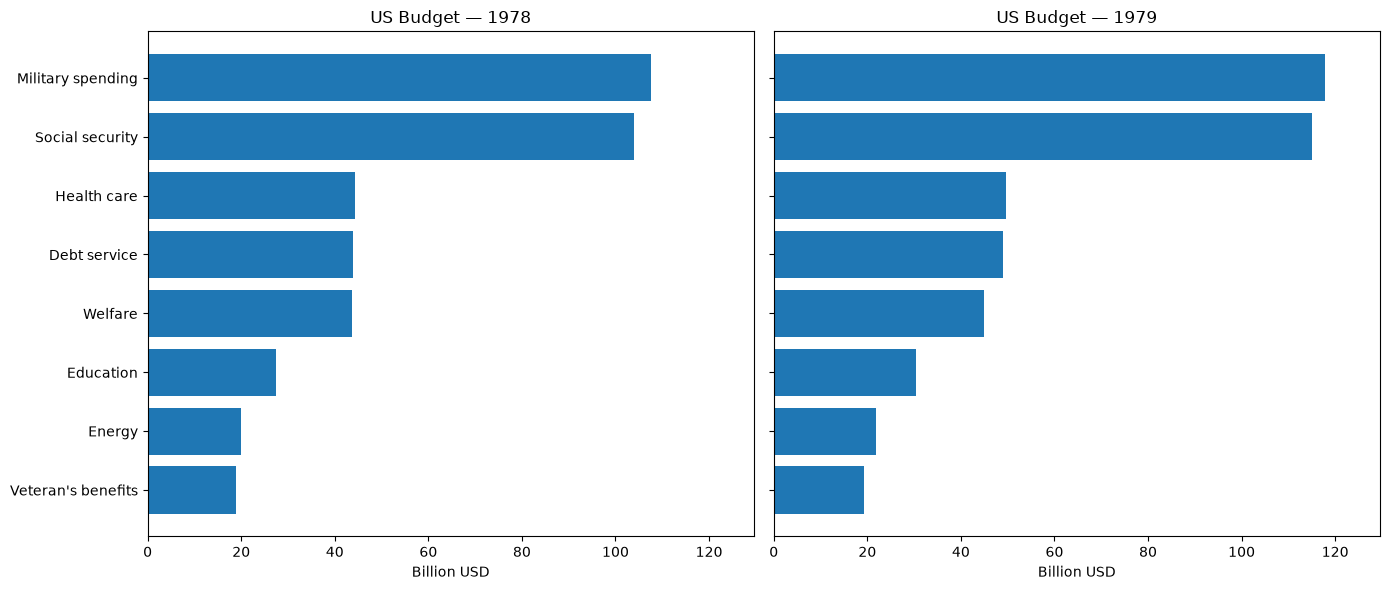

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

axes[0].barh(budget["Category"], budget["1978"])
axes[0].set_title("US Budget — 1978")
axes[0].set_xlabel("Billion USD")
axes[0].invert_yaxis()

axes[1].barh(budget["Category"], budget["1979"])
axes[1].set_title("US Budget — 1979")
axes[1].set_xlabel("Billion USD")

# Use the same scale for a fair comparison
max_budget = max(budget["1978"].max(), budget["1979"].max())

axes[0].set_xlim(0, max_budget * 1.1)
axes[1].set_xlim(0, max_budget * 1.1)

plt.tight_layout()
plt.show()

In [12]:
budget["Difference"] = budget["1979"] - budget["1978"]

display(budget[["Category", "1978", "1979", "Difference"]])

,Category,1978,1979,Difference
0,Military spending,107.6,117.8,10.2
1,Social security,103.9,115.1,11.2
2,Health care,44.3,49.7,5.4
3,Debt service,43.8,49.0,5.2
4,Welfare,43.7,44.9,1.2
5,Education,27.5,30.4,2.9
6,Energy,19.9,21.8,1.9
7,Veteran's benefits,18.9,19.3,0.4


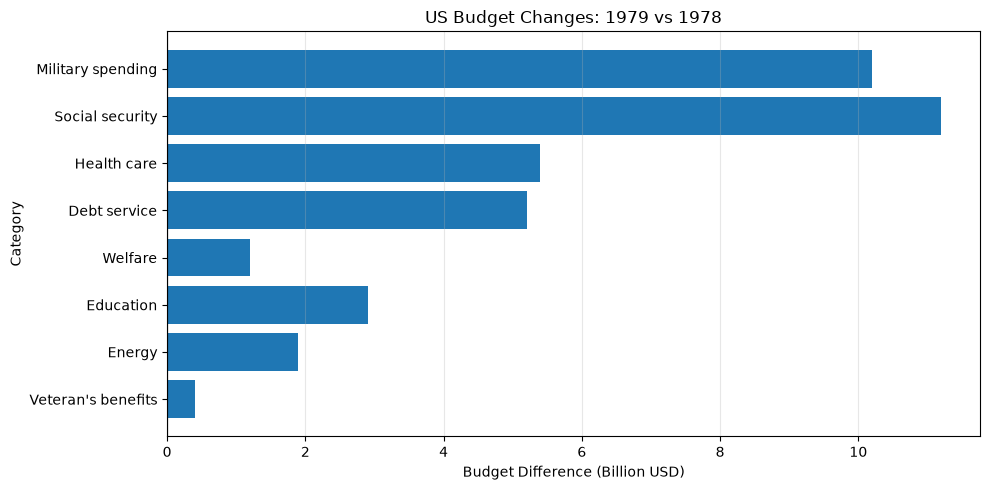

In [13]:
plt.figure(figsize=(10, 5))

plt.barh(budget["Category"], budget["Difference"])

plt.xlabel("Budget Difference (Billion USD)")
plt.ylabel("Category")
plt.title("US Budget Changes: 1979 vs 1978")

plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
# Calculate total budgets
total_1978 = budget["1978"].sum()
total_1979 = budget["1979"].sum()

# Calculate percentage shares
budget["1978 (%)"] = budget["1978"] / total_1978 * 100
budget["1979 (%)"] = budget["1979"] / total_1979 * 100

# Difference in percentage points
budget["Difference (pp)"] = budget["1979 (%)"] - budget["1978 (%)"]

print(f"Total budget 1978: {total_1978:.2f} billion USD")
print(f"Total budget 1979: {total_1979:.2f} billion USD")

display(budget.round(2))

Total budget 1978: 409.60 billion USD
Total budget 1979: 448.00 billion USD


,Category,1978,1979,Difference,1978 (%),1979 (%),Difference (pp)
0,Military spending,107.6,117.8,10.2,26.27,26.29,0.03
1,Social security,103.9,115.1,11.2,25.37,25.69,0.33
2,Health care,44.3,49.7,5.4,10.82,11.09,0.28
3,Debt service,43.8,49.0,5.2,10.69,10.94,0.24
4,Welfare,43.7,44.9,1.2,10.67,10.02,-0.65
5,Education,27.5,30.4,2.9,6.71,6.79,0.07
6,Energy,19.9,21.8,1.9,4.86,4.87,0.01
7,Veteran's benefits,18.9,19.3,0.4,4.61,4.31,-0.31


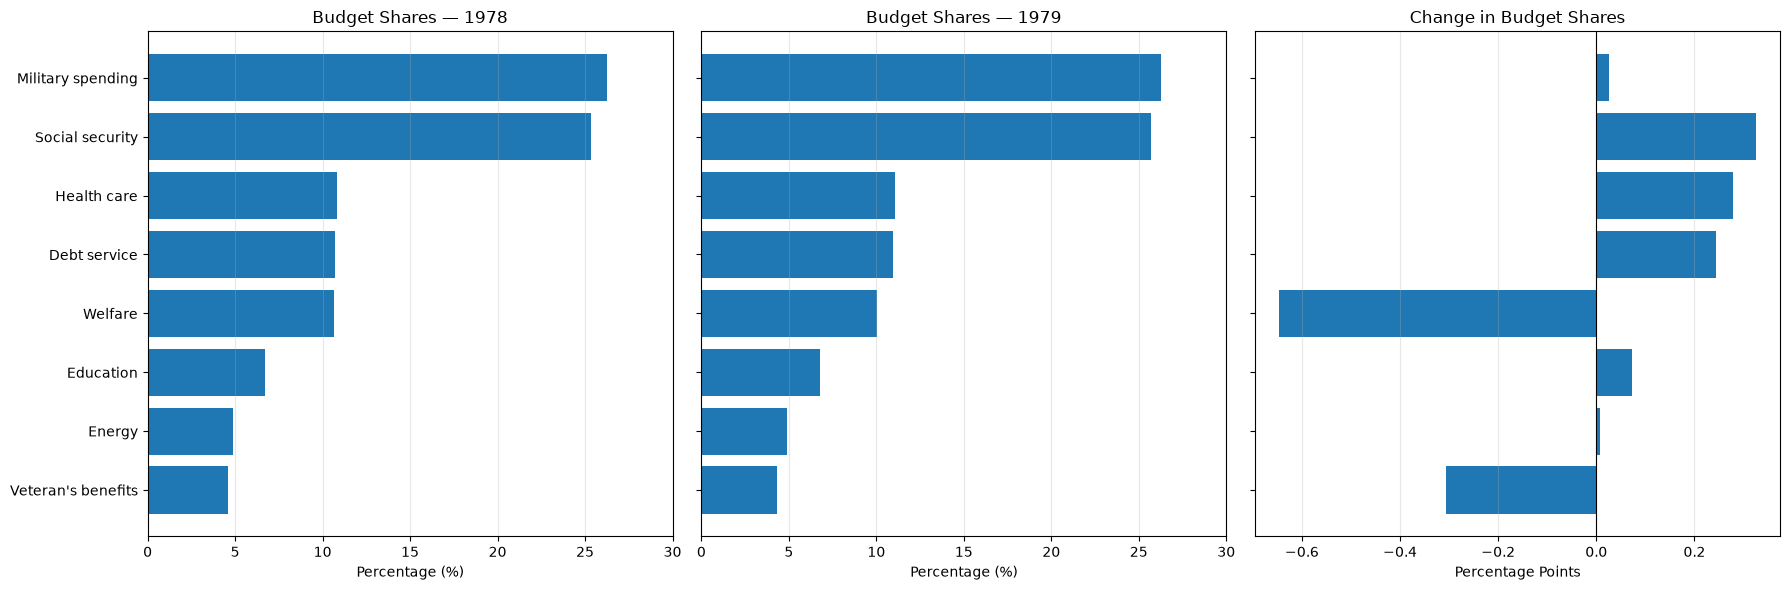

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# Budget shares for 1978
axes[0].barh(budget["Category"], budget["1978 (%)"])
axes[0].set_title("Budget Shares — 1978")
axes[0].set_xlabel("Percentage (%)")
axes[0].invert_yaxis()

# Budget shares for 1979
axes[1].barh(budget["Category"], budget["1979 (%)"])
axes[1].set_title("Budget Shares — 1979")
axes[1].set_xlabel("Percentage (%)")

# Difference in percentage points
axes[2].barh(budget["Category"], budget["Difference (pp)"])
axes[2].set_title("Change in Budget Shares")
axes[2].set_xlabel("Percentage Points")
axes[2].axvline(0, color="black", linewidth=0.8)

# Consistent scale for the first two charts
axes[0].set_xlim(0, 30)
axes[1].set_xlim(0, 30)

for ax in axes:
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusion — US Budget Comparison (1978–1979)

The total budget across the eight categories increased from
**409.60 billion USD** in 1978 to **448.00 billion USD** in 1979.

This represents an increase of **38.40 billion USD (9.38%)**.

**Key findings:**

- All eight categories increased in absolute spending.
- Social security had the largest absolute increase:
  **11.2 billion USD**.
- Social security and health care increased their shares
  of the total budget.
- Welfare decreased by **0.65 percentage points**.
- Veteran's benefits decreased by **0.31 percentage points**.

**Conclusion:**

An increase in absolute spending does not necessarily mean
an increase in the percentage share of the total budget.

Comparing both absolute values and percentage shares provides
a more complete understanding of budget changes.

### Problem 3. Correlations between Variables. Alcohol and Tobacco Usage
The dataset `alcohol_tobacco.dat` shows the average weekly household spending, in British pounds, on tobacco products and alcoholic beverages for each of the 11 regions of Great Britain.

Create a scatter plot. Print the correlation coefficient. You can use the **correlation matrix** (find out how).

There's a major outlier. Which one is it?

Remove the outlier from the dataset (find out how). Calculate the correlation coefficient once again. It should be much higher.

This example is useful to show what an outlier is, and how an outlier can influence the results of an experiment.

**Note:** Be careful with outliers. Sometimes they indicate human error (e.g. human height 1588 cm is obviously wrong) but sometimes they indicate important patterns in the data. Should you remove, replace, or leave them is a difficult question and should be answered separately for each dataset.

In [16]:
# Write your code here
alcohol_tobacco = pd.read_table("alcohol_tobacco.dat")

print("Dataset shape:", alcohol_tobacco.shape)
display(alcohol_tobacco)
print(alcohol_tobacco.dtypes)

Dataset shape: (11, 3)


,Region,Alcohol,Tobacco
0,North,6.47,4.03
1,Yorkshire,6.13,3.76
2,Northeast,6.19,3.77
3,East Midlands,4.89,3.34
4,West Midlands,5.63,3.47
5,East Anglia,4.52,2.92
6,Southeast,5.89,3.20
7,Southwest,4.79,2.71
8,Wales,5.27,3.53
9,Scotland,6.08,4.51


Region         str
Alcohol    float64
Tobacco    float64
dtype: object


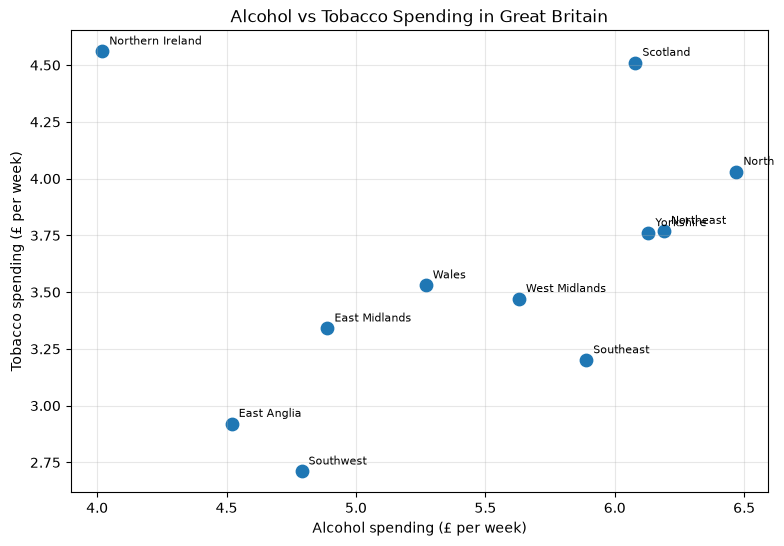

,Alcohol,Tobacco
Alcohol,1.000000,0.223572
Tobacco,0.223572,1.000000


In [17]:
plt.figure(figsize=(9, 6))

plt.scatter(
    alcohol_tobacco["Alcohol"],
    alcohol_tobacco["Tobacco"],
    s=80
)

for _, row in alcohol_tobacco.iterrows():
    plt.annotate(
        row["Region"],
        (row["Alcohol"], row["Tobacco"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Alcohol spending (£ per week)")
plt.ylabel("Tobacco spending (£ per week)")
plt.title("Alcohol vs Tobacco Spending in Great Britain")
plt.grid(alpha=0.3)

plt.show()

# Pearson correlation matrix
correlation_matrix = alcohol_tobacco[["Alcohol", "Tobacco"]].corr()

display(correlation_matrix)

In [18]:
# Create a new dataset without Northern Ireland
data_without_outlier = alcohol_tobacco[
    alcohol_tobacco["Region"] != "Northern Ireland"
].copy()

# Calculate Pearson correlation
correlation_without_outlier = data_without_outlier[
    ["Alcohol", "Tobacco"]
].corr()

print("Original correlation:")
print(correlation_matrix.loc["Alcohol", "Tobacco"])

print("\nCorrelation without Northern Ireland:")
print(correlation_without_outlier.loc["Alcohol", "Tobacco"])

display(correlation_without_outlier)

Original correlation:
0.22357211426264398

Correlation without Northern Ireland:
0.784287320153868


,Alcohol,Tobacco
Alcohol,1.000000,0.784287
Tobacco,0.784287,1.000000


### Conclusion — Alcohol and Tobacco Correlation

The Pearson correlation coefficient for all 11 regions is
**r = 0.2236**, indicating a weak positive linear relationship.

**Northern Ireland** is a major outlier, with relatively low
alcohol spending (£4.02) and high tobacco spending (£4.56).

After excluding Northern Ireland, the correlation increases
to **r = 0.7843**, indicating a strong positive linear relationship.

**Conclusion:**

### Problem 4. Simulation
Another prediction technique based on statistics, is simulation. This means recreating a system's parameters and running the experiment on a computer instead of running it in real life. Simulation can give us many insights. It's useful for prediction, "what-if" analysis, etc. It's also very useful if we have very limited "real experimentation" resources and want to narrow down our possibilities.

Let's see how we can simulate the profit of a grocery shop.

The profit is dependent on the customers and what items they buy. Let's assume that the number of customers per months follows a normal distribution with mean 500 and standard deviation 20.

$$ C \sim N(500, 20) $$

In the shop, there are several items, each having a different popularity. The popularity represents the probability of buying each item.

| Item               | Price | Popularity |
|--------------------|-------|------------|
| Bread              | 0.99  | 0.5        |
| Milk               | 2.89  | 0.15       |
| Eggs, dozen        | 2.00  | 0.2        |
| Chicken fillet, kg | 6.39  | 0.15       |

Each customer buys *exactly one* article at random. Each customer will generate an expected profit equal to $\text{price} . \text{popularity}$. Total profit: sum of all profits.

In [19]:
def get_customer_profit():
    n = np.random.random()
    if n <= 0.5:
        return 0.99
    elif n < 0.65:
        return 2.89
    elif n <= 0.85:
        return 2
    else:
        return 6.39

In [20]:
days = 1000
def run_simulation():
    profits = []
    for day in range(days):
        customers = np.floor(np.random.normal(500, 20))
        profit = sum([get_customer_profit() for c in np.arange(customers)])
        profits.append(profit)
    return profits

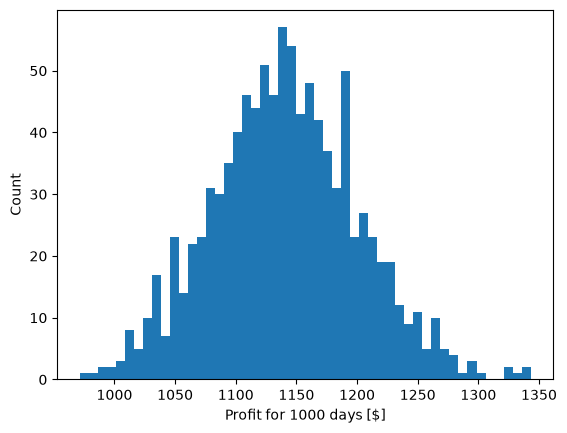

In [21]:
profits = run_simulation()
plt.hist(profits, bins = 50)
plt.xlabel("Profit for " + str(days) + " days [$]")
plt.ylabel("Count")
plt.show()

In [22]:
profits_array = np.array(profits)

mean_profit = profits_array.mean()
std_profit = profits_array.std()

prob_below_1100 = np.mean(profits_array < 1100)

prob_1300_1400 = np.mean(
    (profits_array >= 1300) & (profits_array <= 1400)
)

print(f"Mean revenue: ${mean_profit:.2f}")
print(f"Standard deviation: ${std_profit:.2f}")
print(f"P(Revenue < 1100): {prob_below_1100:.4f}")
print(f"P(1300 <= Revenue <= 1400): {prob_1300_1400:.4f}")

Mean revenue: $1140.92
Standard deviation: $60.26
P(Revenue < 1100): 0.2460
P(1300 <= Revenue <= 1400): 0.0060


Now we can answer questions like:
* What's the probability of profit less than \$1100? 
* What's the probability of profit between \$1300 and \$1400?

We can also change our model. Let's suppose now that one customer can take 1, 2 or 3 items, with probabilities 0.5, 0.3 and 0.2 respectively. The picked items are independent. How does this change the distribution?

In [23]:
def get_customer_profit_many_items(items = 1):
    customer_sum = sum([get_customer_profit() for i in range(items)])
    return customer_sum

def get_total_customer_profit():
    n = np.random.random()
    if n <= 0.5:
        return get_customer_profit_many_items(1)
    elif n <= 0.8:
        return get_customer_profit_many_items(2)
    else:
        return get_customer_profit_many_items(3)

In [24]:
def run_simulation_many_items():
    days = 1000
    profits_many_items = []
    for day in range(days):
        customers = np.floor(np.random.normal(500, 20))
        profit = sum([get_total_customer_profit() for c in np.arange(customers)])
        profits_many_items.append(profit)
    return profits_many_items

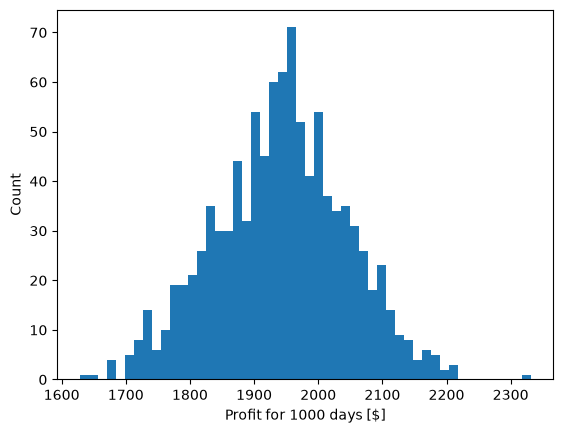

In [25]:
profits_many_items = run_simulation_many_items()
plt.hist(profits_many_items, bins = 50)
plt.xlabel("Profit for " + str(days) + " days [$]")
plt.ylabel("Count")
plt.show()

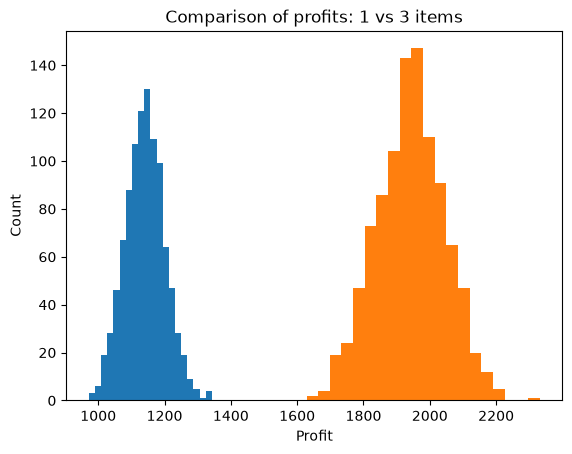

In [26]:
plt.title("Comparison of profits: 1 vs 3 items")
plt.hist(profits, bins = 20)
plt.hist(profits_many_items, bins = 20)
plt.xlabel("Profit")
plt.ylabel("Count")
plt.show()

In [27]:
print("MODEL 1 — One item per customer")
print(f"Mean: ${np.mean(profits):.2f}")
print(f"Std:  ${np.std(profits):.2f}")

print("\nMODEL 2 — One to three items per customer")
print(f"Mean: ${np.mean(profits_many_items):.2f}")
print(f"Std:  ${np.std(profits_many_items):.2f}")

increase = (
    (np.mean(profits_many_items) / np.mean(profits) - 1) * 100
)

print(f"\nRevenue increase: {increase:.2f}%")

MODEL 1 — One item per customer
Mean: $1140.92
Std:  $60.26

MODEL 2 — One to three items per customer
Mean: $1942.27
Std:  $103.01

Revenue increase: 70.24%


### Conclusion — Grocery Shop Simulation

The Monte Carlo simulation compared two purchasing models over 1,000 simulated periods.

| Metric | One item | One to three items |
|---|---:|---:|
| Mean revenue | $1140.92 | $1942.27 |
| Standard deviation | $60.26 | $103.01 |
| Theoretical expected revenue | $1143.50 | $1943.95 |

**Key findings:**

- The average revenue increased by **70.24%**.
- The standard deviation increased from **$60.26** to **$103.01**.
- Both simulated means are close to their theoretical expected values.
- Purchasing multiple items increases both expected revenue and absolute variability.

**Conclusion:**

Monte Carlo simulation is useful for estimating expected outcomes and evaluating uncertainty.

Allowing customers to purchase 1–3 items instead of exactly one increases average revenue by approximately **70%**.

**Note:** The simulation calculates revenue, not net profit, because product costs are not included.

### Problem 5. Image Convolution
"Convolution" refers to a process similar to "mixing" two functions. It can be performed in one dimension (e.g. on audio data), or many dimensions. In this problem, we'll look at 2D convolution of images and what we can do with it.

Let's first read an image. Once again, to make things easier, we'll separate the channels. We can work on all three channels separately or at once but it's easier to work with one channel only.

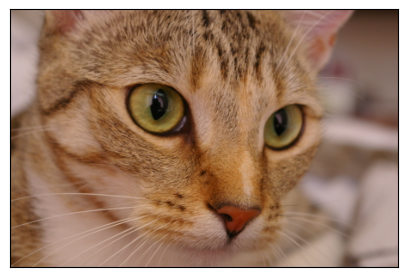

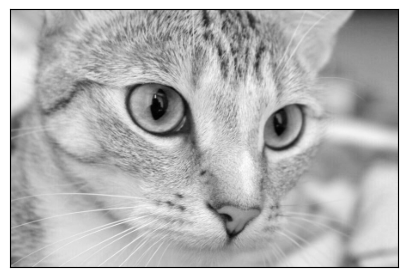

In [30]:
from skimage import data

original_image = data.chelsea()

def display(image):
    # If there is only one channel to show, display it as grayscale
    cm = None
    if(len(image.shape)) == 2:
        cm = "gray"
    plt.figure(figsize = (5, 10))
    plt.imshow(image, cmap = cm)
    plt.xticks([])
    plt.yticks([])
    plt.show()

display(original_image)
r = original_image[:, :, 0]
display(r)

**Convolution** means taking a special square matrix (usually 3x3 or 5x5), called a **convolution kernel** and applying it to the image like this: the central pixel of the resulting image is the sum of element-wise products between the image and the kernel:
![Convolution example](convolution.png)

After that, the kernel moves 1px to the right and contiinues. It "slides" across the entire image. The edge pixels are a bit problematic but there are several ways to deal with that. The most common way is to copy whatever pixel value happened to be at the border.

![Border handling](border.png)

The algorithm is always the same. The output depends on the **kernel**. Different kernels produce different results: some detect edges (lines), others detect corners; some apply blurring and sharpening; some remove noise, etc.

The results can be useful for analyzing what's on the image, or just for artistic purposes.

Let's examine this filter, for example:

$$ F = \begin{bmatrix}
1/9 & 1/9 & 1/9 \\
1/9 & 1/9 & 1/9 \\
1/9 & 1/9 & 1/9
\end{bmatrix}
$$

This calculates the average of all surrounding pixels and basically smooths the image.

Note that in order to preserve brightness, the sum of all elements in $F$ must be equal to 1. If it's not, the image will be darker or brighter (which may or may not be a desired effect).

`scipy.ndimage` has a method for performing 1D and multi-dimensional convolution. Read the docs [here](https://docs.scipy.org/doc/scipy-0.15.1/reference/generated/scipy.ndimage.filters.convolve.html#scipy.ndimage.filters.convolve).

Apply the convolution. To see better how it performs, you can plot only a part of the image - this will zoom the entire thing. Compare the "before" and "after" images.

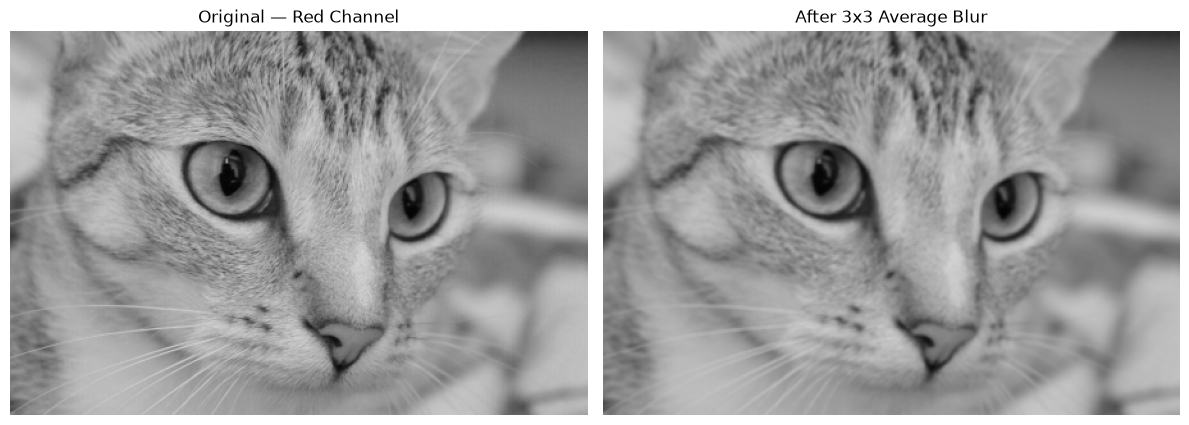

In [31]:
# Write your code here
from scipy.ndimage import convolve

# 3x3 averaging kernel
kernel = np.ones((3, 3), dtype=float) / 9

# Apply convolution to the red channel
blurred = convolve(r.astype(float), kernel, mode="nearest")

# Compare original and filtered images
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(r, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original — Red Channel")
axes[0].axis("off")

axes[1].imshow(blurred, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("After 3x3 Average Blur")
axes[1].axis("off")

plt.tight_layout()
plt.show()

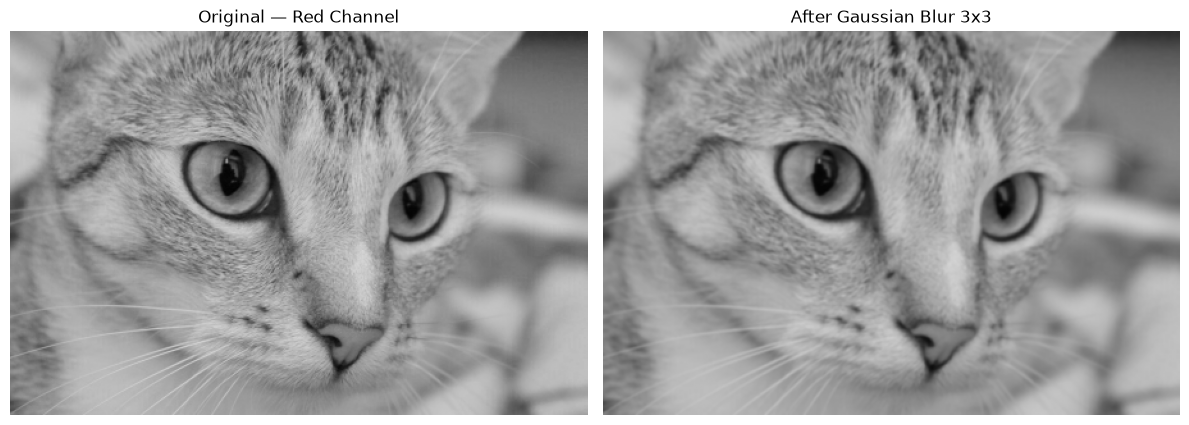

In [32]:
# Gaussian blur kernel (3x3)
gaussian_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=float) / 16

gaussian_blurred = convolve(
    r.astype(float),
    gaussian_kernel,
    mode="nearest"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(r, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original — Red Channel")
axes[0].axis("off")

axes[1].imshow(gaussian_blurred, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("After Gaussian Blur 3x3")
axes[1].axis("off")

plt.tight_layout()
plt.show()

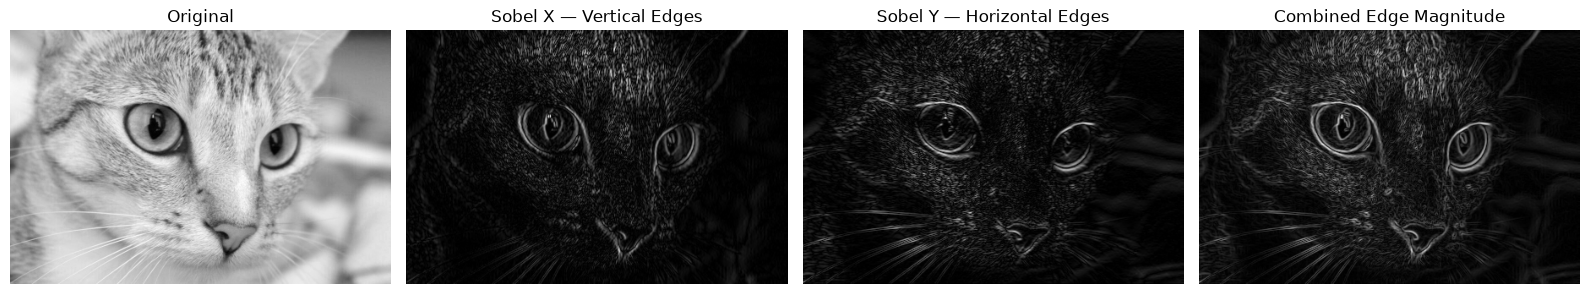

In [33]:
# Sobel kernels
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=float)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=float)

# Apply Sobel filters
edges_x = convolve(r.astype(float), sobel_x, mode="nearest")
edges_y = convolve(r.astype(float), sobel_y, mode="nearest")

# Combined gradient magnitude
edges_combined = np.hypot(edges_x, edges_y)

# Display results
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

images = [r, np.abs(edges_x), np.abs(edges_y), edges_combined]
titles = [
    "Original",
    "Sobel X — Vertical Edges",
    "Sobel Y — Horizontal Edges",
    "Combined Edge Magnitude"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

Play around with more kernels (they're also called **filters**). You can find examples on the Internet, or you can create your own. Have fun :).

Try these filters:
* Gaussian blur
* Sobel edge detector - vertical, horizontal
* Corner detector
* Gradient detector
* Sharpening
* Unsharp mask

For each filter, show the result before and after its application.

Sources: <a href="https://en.wikipedia.org/wiki/Kernel_(image_processing)">Wikipedia</a>, [Image Kernels explained visually](http://setosa.io/ev/image-kernels/).

**Optional:** Think about you might use edge, corner and gradient detectors in image processing.

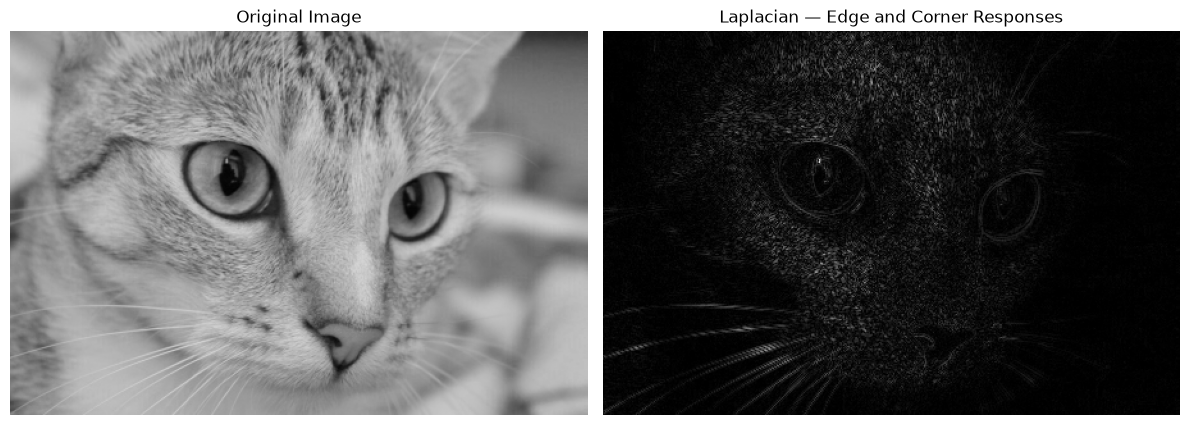

In [34]:
# Write your code here
# Laplacian kernel (8-neighbor)
laplacian_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=float)

# Apply convolution
laplacian_result = convolve(
    r.astype(float),
    laplacian_kernel,
    mode="nearest"
)

# Display original and filtered images
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(r, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(np.abs(laplacian_result), cmap="gray")
axes[1].set_title("Laplacian — Edge and Corner Responses")
axes[1].axis("off")

plt.tight_layout()
plt.show()

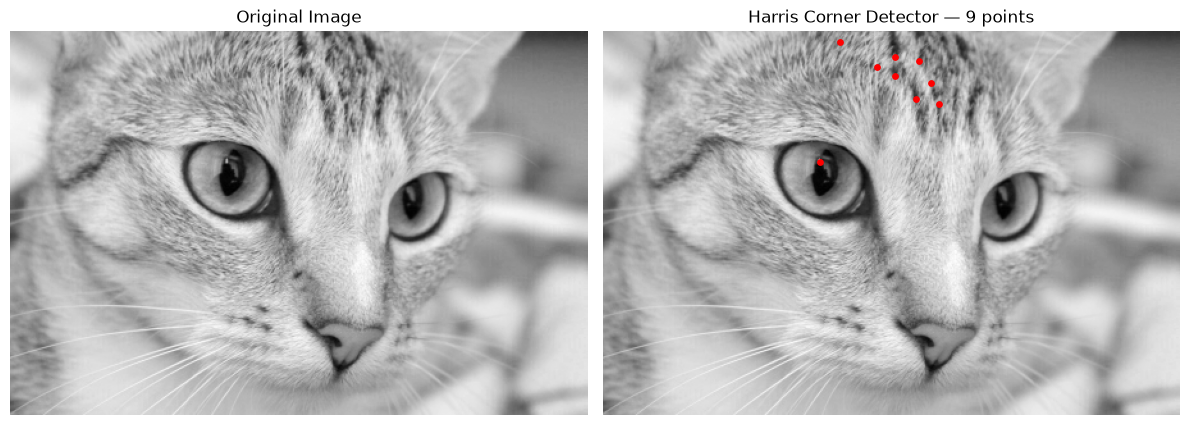

Detected corners: 9


In [35]:
from skimage.feature import corner_harris, corner_peaks
from skimage.util import img_as_float

# Convert the red channel to floating-point values
image_float = img_as_float(r)

# Calculate Harris corner response
harris_response = corner_harris(image_float)

# Find corner coordinates
corners = corner_peaks(
    harris_response,
    min_distance=5,
    threshold_rel=0.05
)

# Display detected corners
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(r, cmap="gray")
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(r, cmap="gray")
axes[1].scatter(
    corners[:, 1],
    corners[:, 0],
    s=15,
    c="red",
    marker="o"
)
axes[1].set_title(f"Harris Corner Detector — {len(corners)} points")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Detected corners:", len(corners))

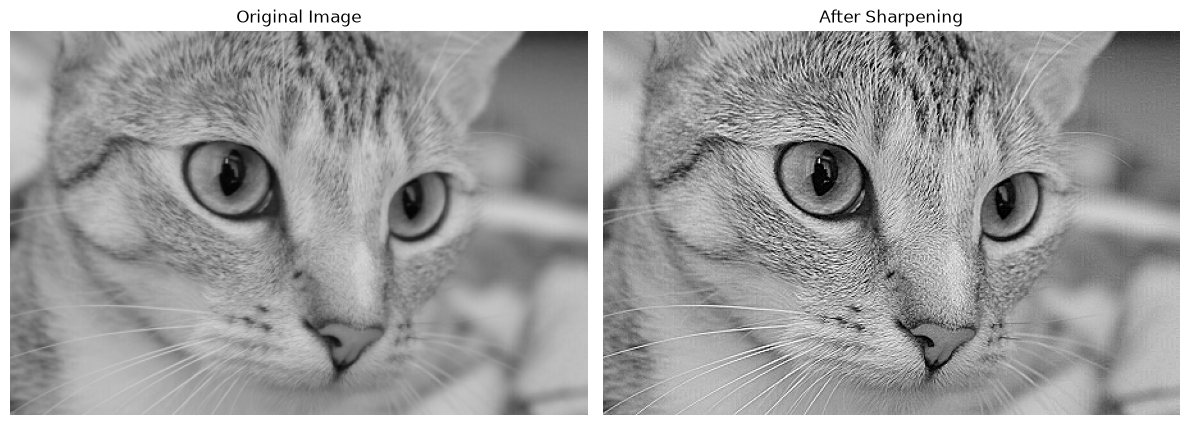

In [36]:
# Sharpening kernel
sharpen_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=float)

# Apply sharpening
sharpened = convolve(
    r.astype(float),
    sharpen_kernel,
    mode="nearest"
)

# Keep pixel values in the valid range
sharpened = np.clip(sharpened, 0, 255)

# Compare original and sharpened images
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(r, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(sharpened, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("After Sharpening")
axes[1].axis("off")

plt.tight_layout()
plt.show()

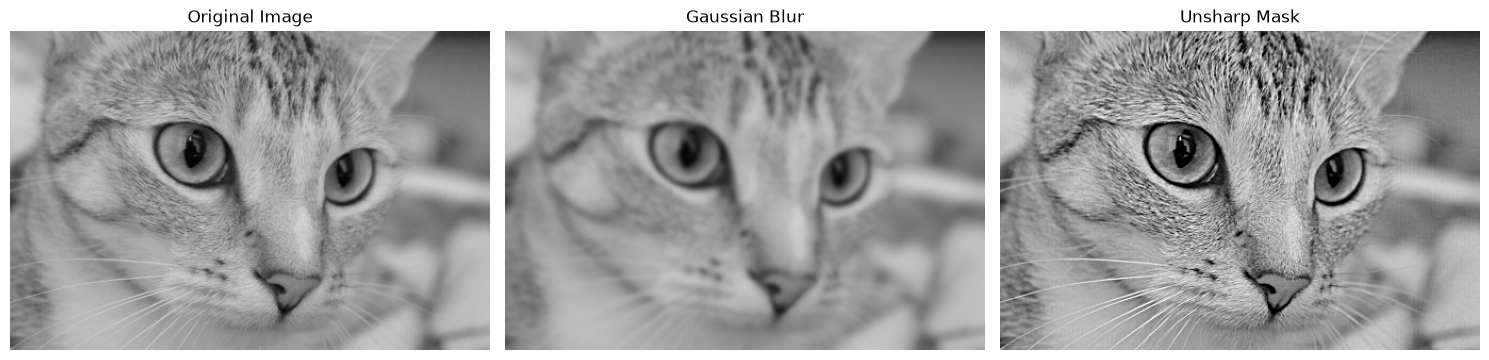

In [37]:
from scipy.ndimage import gaussian_filter

# Convert the red channel to float
image_float = r.astype(float)

# Create a blurred version
blurred_image = gaussian_filter(image_float, sigma=2)

# Unsharp mask
amount = 1.5
unsharp_image = image_float + amount * (
    image_float - blurred_image
)

# Keep pixel values between 0 and 255
unsharp_image = np.clip(unsharp_image, 0, 255)

# Compare results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [r, blurred_image, unsharp_image]
titles = [
    "Original Image",
    "Gaussian Blur",
    "Unsharp Mask"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Conclusion — Image Convolution

In this exercise, several image-processing filters were applied
to the red channel of a cat image.

- **Average Blur:** Smooths the image by averaging neighboring pixels.
- **Gaussian Blur:** Produces smoother transitions and reduces fine details.
- **Sobel Filters:** Detect horizontal and vertical intensity changes.
- **Gradient Magnitude:** Combines directional gradients to highlight edges.
- **Laplacian Filter:** Highlights rapid intensity changes, including edges and corners.
- **Harris Corner Detector:** Identified 9 feature points in the image.
- **Sharpening:** Enhances edges and fine details.
- **Unsharp Mask:** Improves sharpness by adding high-frequency details
  extracted using a blurred version of the image.

**Conclusion:**

Different filters produce different results because they use
different mathematical operations.

Blurring filters reduce fine details, edge detectors highlight
intensity changes, and sharpening filters enhance image details.

The experiments demonstrate how convolution and related
image-processing techniques can be used for feature extraction,
image enhancement, and computer vision.

**Practical applications:** Object recognition, image analysis,
medical imaging, robotics, and automated visual inspection.

###  Problem 6. Monte Carlo Simulation
One common technique to apply simulations is called **Monte Carlo simulation**. It's similar to the simulation from the previous example. The main idea is to use random sampling to solve deterministic problems.

Research what these simulations are. Give examples. Implement at least one case of a Monte Carlo simulation. You can use the following checklist to help with your research and work:
* What is a simulation?
    * How is simulation used in science?
    * Why is a simulation useful?
* How are statistics useful in simulation? How can we simulate unknown, random processes?
* What is a Monte Carlo simulation (also known as "Monte Carlo method")?
* A common use of Monte Carlo methods is numeric integration
    * Define the problem. Propose the solution. Implement it and test with some common functions
    * How does this method compare to other methods, e.g. the trapezoidal rule? Compare the performance (accuracy and time to execute) of both methods
* Apply Monte Carlo simulation to a real-life system. There are many examples. You can see [Wikipedia](https://en.wikipedia.org/wiki/Monte_Carlo_method#Applications) or some other resource for inspiration.

Use a library, like PyMC3, to make an in-depth analysis. If you're additionally interested in the topic, look up "probabilistic programming".

### 1. Introduction to Simulation and Monte Carlo Methods

**What is a simulation?**

A simulation is a computational model of a real or mathematical
system. It allows us to study the system's behavior without
performing the experiment in real life.

**How are simulations used in science?**

Simulations are used in physics, engineering, medicine,
economics, meteorology, and computer science.

Examples include:
- Weather forecasting
- Modeling the movement of particles
- Financial risk analysis
- Traffic simulations
- Reliability testing of engineering systems

**Why are simulations useful?**

Simulations allow researchers to:
- Test different scenarios
- Estimate possible outcomes
- Study complex systems
- Reduce experimental costs and risks
- Investigate systems that are difficult to analyze analytically

### 2. Statistics and Random Processes

Statistics helps us describe uncertainty using probability
distributions, expected values, variance, and standard deviation.

Random processes can be simulated by generating samples from
probability distributions.

For example, the number of customers visiting a store can be
modeled using a normal distribution.

Repeated simulations allow us to estimate the expected outcome
and its variability.

### 3. What Is the Monte Carlo Method?

The Monte Carlo method is a computational technique that uses
random sampling to estimate numerical quantities.

It is particularly useful when an exact mathematical solution
is difficult or computationally expensive.

Common applications include:
- Numerical integration
- Probability estimation
- Financial risk modeling
- Engineering reliability analysis
- Physics simulations

**Main principle:**

Generate many random samples, evaluate the mathematical model,
and use statistical averages to estimate the desired result.

As the number of samples increases, the estimate generally
becomes more accurate, although individual runs may fluctuate.

In [38]:
import numpy as np

# Function to integrate
def f(x):
    return x**2

# Exact value of the integral
exact_value = 1 / 3

# Monte Carlo integration
def monte_carlo_integral(func, a, b, n_samples, rng):
    x = rng.uniform(a, b, n_samples)
    return (b - a) * np.mean(func(x))

# Reproducible random generator
rng = np.random.default_rng(42)

# Number of random samples
n_samples = 10000

# Calculate integral
mc_result = monte_carlo_integral(
    f, 0, 1, n_samples, rng
)

# Calculate absolute error
absolute_error = abs(mc_result - exact_value)

print(f"Exact integral:       {exact_value:.8f}")
print(f"Monte Carlo estimate: {mc_result:.8f}")
print(f"Absolute error:       {absolute_error:.8f}")
print(f"Number of samples:    {n_samples}")


Exact integral:       0.33333333
Monte Carlo estimate: 0.33019287
Absolute error:       0.00314046
Number of samples:    10000


In [40]:
import time
import numpy as np
import matplotlib.pyplot as plt

def trapezoidal_integral(func, a, b, n):
    x = np.linspace(a, b, n + 1)
    y = func(x)
    h = (b - a) / n
    return h * (y[0] / 2 + np.sum(y[1:-1]) + y[-1] / 2)

sample_sizes = [100, 1000, 10000, 100000]
results = []

for n in sample_sizes:
    rng = np.random.default_rng(42)

    # Monte Carlo
    start = time.perf_counter()
    mc = monte_carlo_integral(f, 0, 1, n, rng)
    mc_time = time.perf_counter() - start

    # Trapezoidal rule
    start = time.perf_counter()
    trap = trapezoidal_integral(f, 0, 1, n)
    trap_time = time.perf_counter() - start

    results.append({
        "Samples": n,
        "MC Error": abs(mc - exact_value),
        "Trap Error": abs(trap - exact_value),
        "MC Time (ms)": mc_time * 1000,
        "Trap Time (ms)": trap_time * 1000
    })

import pandas as pd

comparison = pd.DataFrame(results)
print(comparison.to_string(index=False))

 Samples  MC Error   Trap Error  MC Time (ms)  Trap Time (ms)
     100  0.022319 1.666667e-05        0.1515          0.1112
    1000  0.001210 1.666667e-07        0.0632          0.0701
   10000  0.003140 1.666667e-09        0.1266          0.0886
  100000  0.000535 1.666672e-11        0.8182          0.3318


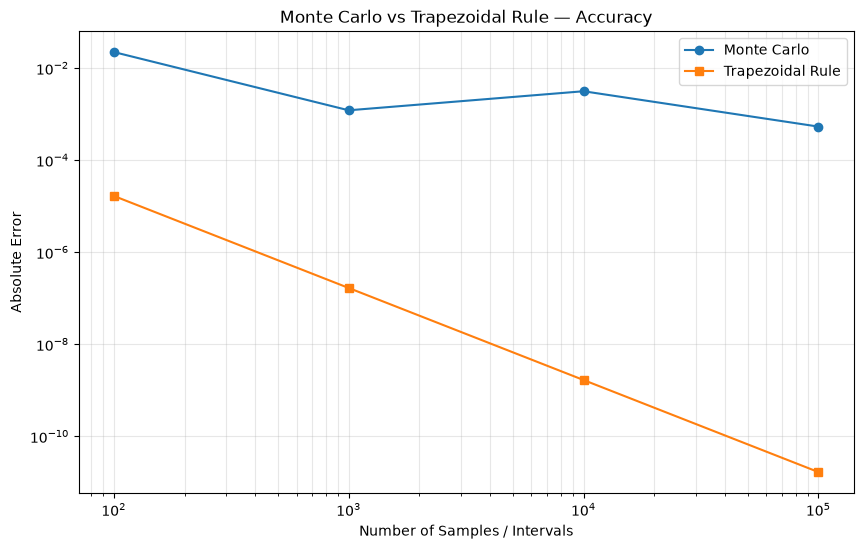

In [41]:
plt.figure(figsize=(10, 6))

plt.loglog(
    comparison["Samples"],
    comparison["MC Error"],
    marker="o",
    label="Monte Carlo"
)

plt.loglog(
    comparison["Samples"],
    comparison["Trap Error"],
    marker="s",
    label="Trapezoidal Rule"
)

plt.xlabel("Number of Samples / Intervals")
plt.ylabel("Absolute Error")
plt.title("Monte Carlo vs Trapezoidal Rule — Accuracy")

plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

### Numerical Integration — Results and Discussion

The integral of f(x) = x² over the interval [0, 1] was
calculated using two numerical methods:

1. Monte Carlo Integration
2. Trapezoidal Rule

The exact value of the integral is 1/3 ≈ 0.33333333.

**Observations:**

- The Monte Carlo method approximates the integral using
  randomly generated samples.
- Its error generally decreases as the number of samples
  increases, but individual results may fluctuate.
- The trapezoidal rule produces significantly smaller errors
  for this smooth one-dimensional function.
- At 100,000 samples, the Monte Carlo absolute error was
  approximately 0.000535, compared with 1.67 × 10⁻¹¹
  for the trapezoidal rule.
- In this experiment, the trapezoidal rule was also faster
  at 100,000 intervals, although repeated timing measurements
  would be needed for a reliable performance comparison.

**Conclusion:**

The trapezoidal rule is more accurate for this particular
one-dimensional integration problem.

However, Monte Carlo methods are valuable for high-dimensional
integration, complex probability models, and simulations
involving uncertainty.

The experiment demonstrates that the most suitable numerical
method depends on the structure and complexity of the problem.

Simulated days: 10000
Mean daily revenue: $1942.04
Standard deviation: $101.33
95% simulation interval: $1749.44 - $2143.60
P(Revenue < $1000): 0.0000


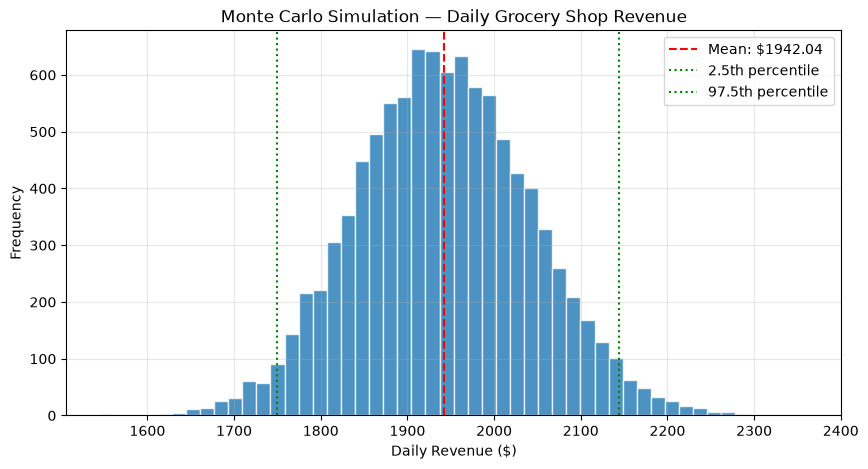

In [42]:
# Monte Carlo simulation — Grocery shop revenue risk

import numpy as np
import matplotlib.pyplot as plt

# Reproducible simulation
np.random.seed(42)

# Run 10,000 simulated business days
simulations = 10000

revenues = []

for _ in range(simulations):
    customers = max(0, int(np.floor(np.random.normal(500, 20))))

    daily_revenue = sum(
        get_total_customer_profit()
        for _ in range(customers)
    )

    revenues.append(daily_revenue)

revenues = np.array(revenues)

# Statistical analysis
mean_revenue = np.mean(revenues)
std_revenue = np.std(revenues)
lower_bound, upper_bound = np.percentile(revenues, [2.5, 97.5])
risk_probability = np.mean(revenues < 1000)

print(f"Simulated days: {simulations}")
print(f"Mean daily revenue: ${mean_revenue:.2f}")
print(f"Standard deviation: ${std_revenue:.2f}")
print(f"95% simulation interval: ${lower_bound:.2f} - ${upper_bound:.2f}")
print(f"P(Revenue < $1000): {risk_probability:.4f}")

# Visualization
plt.figure(figsize=(10, 5))
plt.hist(revenues, bins=50, alpha=0.8, edgecolor="white")

plt.axvline(mean_revenue, color="red", linestyle="--",
            label=f"Mean: ${mean_revenue:.2f}")

plt.axvline(lower_bound, color="green", linestyle=":",
            label="2.5th percentile")
plt.axvline(upper_bound, color="green", linestyle=":",
            label="97.5th percentile")

plt.title("Monte Carlo Simulation — Daily Grocery Shop Revenue")
plt.xlabel("Daily Revenue ($)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Conclusion — Problem 6: Monte Carlo Simulation

A Monte Carlo simulation was performed to estimate the daily revenue of a grocery shop under uncertain customer demand and purchasing behavior.

The simulation generated **10,000 business days**, assuming that the number of customers follows a normal distribution with a mean of 500 and a standard deviation of 20. Each customer purchases between one and three items according to the specified probabilities.

#### Simulation Results

- **Simulated days:** 10,000
- **Mean daily revenue:** $1,942.04
- **Standard deviation:** $101.33
- **95% simulation interval:** $1,749.44 – $2,143.60
- **Estimated probability of revenue below $1,000:** 0.0000

#### Analysis

The histogram shows an approximately bell-shaped distribution, with most simulated revenues concentrated around the mean.

The 95% simulation interval indicates that approximately 95% of the simulated daily revenues fall between **$1,749.44 and $2,143.60**.

No simulated day produced revenue below $1,000. However, this does not mean that such an event is mathematically impossible.

#### Final Conclusion

Monte Carlo simulation is a useful statistical technique for modeling uncertainty, estimating expected outcomes, and evaluating financial risk.

The experiment demonstrates how random sampling can help predict the behavior of a real-world system.

In the earlier numerical integration experiment, the trapezoidal rule was more accurate than Monte Carlo integration for the smooth function tested. However, Monte Carlo methods are particularly valuable for analyzing complex systems influenced by random variables.

**Note:** The model estimates revenue rather than net profit because product costs and operating expenses are not included.

### ** Problem 7. Classification
A type of widely used **models** is **classification**. Regression outputs a continuous value while classification outputs one of several pre-defined classes. In the most simple way, the classes are only two. For example, if we want to detect whether there's a cat on an image, we can have two classes: "cat" and "non-cat".

Explore the problem of classification. Implement and document one algorithm. Apply it to some real-world data. You can use the following checklist:

**Note:** If your paper is **about the algorithm**, consider **writing it from scratch**, not reusing it from a library.

* What is supervised learning? What do supervised learning models do?
* What is regression? What is classification?
* What types of problems does classification solve directly?
    * What types of problems can be reduced to classification?
* What's the difference between two-class and multi-class classification?
* Explore one algorithm for classification, e.g. logistic regression.
    * State the problem clearly
    * List all sssumptions of the modelling function
    * Describe the process: distances, error function, total loss, gradient descent, etc.; as needed
    * Implement the algorithm from scratch
* Select or generate a small dataset, suitable for classification. Run your algorithm as a sanity check
* Debug and solve any problems
* Waht is a confusion matrix?
* What metrics are used to score a classifier?
    * Accuracy, Precision, Recall, others
    * ROC curve, interpretation
* Select a real dataset
    * Explore it to get acquainted with what information it contains
    * Clean up the data if you need to do so
    * Perform classification
    * Score your classification model
    * Use your classifier to predict
        * Split the data into training and testing set
        * Optionally, perform **cross-validation**
    * Compare your implementation to another one, e.g. `scikit-learn`. They should give the same (or very similar) results
    * Communicate the results on your dataset
    * Optionally, publish your model on the Internet as a Web API

### 7.1 Introduction to Classification

#### Supervised Learning

Supervised learning is a machine learning approach in which a model
learns from labeled examples.

Each training example contains:
- Input features (X)
- A known target value or class (y)

The objective is to learn a relationship between inputs and outputs
that generalizes to previously unseen data.

#### Regression vs Classification

Regression predicts continuous numerical values.

Examples:
- Predicting house prices
- Forecasting temperature
- Estimating energy consumption

Classification predicts discrete categories or classes.

Examples:
- Email classification: spam or not spam
- Medical diagnosis: benign or malignant
- Image recognition: cat or non-cat
- Fraud detection: fraudulent or legitimate transaction

#### Binary vs Multiclass Classification

Binary classification involves exactly two classes.

Examples:
- 0 = Benign
- 1 = Malignant

Multiclass classification involves more than two classes.

Examples:
- Iris flower classification: Setosa, Versicolor, Virginica
- Handwritten digit recognition: 0–9

#### Selected Algorithm: Logistic Regression

Logistic Regression is a supervised learning algorithm commonly used
for binary classification.

It estimates the probability that an observation belongs to a
particular class.

The model uses the sigmoid function:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

where:

$$
z = w_1x_1 + w_2x_2 + \cdots + w_nx_n + b
$$

The predicted probability is:

$$
P(y=1 \mid X) = \sigma(w^T X + b)
$$

Using a decision threshold of 0.5:

$$
\hat{y} =
\begin{cases}
1, & P(y=1 \mid X) \geq 0.5 \\
0, & P(y=1 \mid X) < 0.5
\end{cases}
$$

In this exercise, Logistic Regression will first be implemented
from scratch using NumPy and then compared with scikit-learn.

### 7.2 Mathematical Foundations of Logistic Regression

#### 1. Linear Model and Sigmoid Function

Logistic Regression first calculates a linear combination of the input features:

$$
z = w^T X + b
$$

where:
- $X$ is the input feature vector.
- $w$ is the vector of model weights.
- $b$ is the bias term.

The sigmoid function transforms this value into a probability:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

The predicted probability is:

$$
\hat{p} = \sigma(w^T X + b)
$$

The result is always between 0 and 1.

#### 2. Binary Cross-Entropy Loss

To measure prediction errors, we use Binary Cross-Entropy (Log Loss):

$$
L(y,\hat{p}) =
-\left[
y\ln(\hat{p}) +
(1-y)\ln(1-\hat{p})
\right]
$$

where:
- $y$ is the true class label (0 or 1).
- $\hat{p}$ is the predicted probability.

For $m$ training examples, the average loss is:

$$
J(w,b) =
-\frac{1}{m}
\sum_{i=1}^{m}
\left[
y_i\ln(\hat{p}_i) +
(1-y_i)\ln(1-\hat{p}_i)
\right]
$$

The objective is to minimize this loss.

#### 3. Gradient Descent

Gradient Descent is an optimization algorithm that updates model
parameters in the direction that reduces the loss.

The gradients are:

$$
\frac{\partial J}{\partial w}
=
\frac{1}{m}X^T(\hat{p}-y)
$$

$$
\frac{\partial J}{\partial b}
=
\frac{1}{m}\sum_{i=1}^{m}(\hat{p}_i-y_i)
$$

The parameter updates are:

$$
w := w-\alpha\frac{\partial J}{\partial w}
$$

$$
b := b-\alpha\frac{\partial J}{\partial b}
$$

where $\alpha$ is the learning rate.

These updates are repeated for a specified number of iterations
until the model approaches a minimum of the loss function.

#### 4. Model Assumptions

The implementation uses the following assumptions:

1. The target variable contains two classes: 0 and 1.
2. Training observations are independent.
3. The log-odds of the positive class are modeled as a linear
   combination of the input features.
4. The input features are numerical.
5. Feature scaling is recommended for stable gradient descent.
6. The training and testing datasets must remain separate to
   avoid data leakage.

#### 5. Training Process

The algorithm follows these steps:

1. Initialize weights and bias to zero.
2. Calculate predicted probabilities using the sigmoid function.
3. Calculate the Binary Cross-Entropy loss.
4. Compute gradients for weights and bias.
5. Update parameters using Gradient Descent.
6. Repeat until the specified number of iterations is reached.
7. Convert probabilities into class predictions using a threshold.

### 7.3 Logistic Regression from Scratch

We implement binary Logistic Regression using NumPy.

The model uses:
- A linear combination of input features and weights.
- The sigmoid function to estimate probabilities.
- Binary Cross-Entropy as the loss function.
- Batch Gradient Descent to optimize the parameters.

The implementation provides three main methods:

- `fit(X, y)` — trains the model.
- `predict_proba(X)` — predicts class probabilities.
- `predict(X)` — predicts binary class labels.

The training loss is recorded to analyze convergence.

In [43]:
import numpy as np
import matplotlib.pyplot as plt


class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.1, n_iterations=2000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()

        n_samples, n_features = X.shape

        if not np.all(np.isin(y, [0, 1])):
            raise ValueError("Target labels must be 0 or 1.")

        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []

        for _ in range(self.n_iterations):
            # Forward propagation
            z = X @ self.weights + self.bias
            probabilities = self.sigmoid(z)

            # Binary Cross-Entropy loss
            eps = 1e-15
            p = np.clip(probabilities, eps, 1 - eps)

            loss = -np.mean(
                y * np.log(p) +
                (1 - y) * np.log(1 - p)
            )

            self.loss_history.append(loss)

            # Calculate gradients
            errors = probabilities - y

            dw = (X.T @ errors) / n_samples
            db = np.mean(errors)

            # Update parameters
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

        return self

    def predict_proba(self, X):
        if self.weights is None:
            raise ValueError("The model must be fitted first.")

        X = np.asarray(X, dtype=float)
        z = X @ self.weights + self.bias

        return self.sigmoid(z)

    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)

In [44]:
model = LogisticRegressionScratch(
    learning_rate=0.1,
    n_iterations=2000
)

print("Model created successfully.")
print("Learning rate:", model.learning_rate)
print("Iterations:", model.n_iterations)
print("Initial weights:", model.weights)

Model created successfully.
Learning rate: 0.1
Iterations: 2000
Initial weights: None


### 7.4 Sanity Check — Synthetic Dataset

Before applying the model to real-world data, we test it on a small
synthetic binary classification dataset.

The dataset contains two numerical features and two classes (0 and 1).

The objectives are:

1. Train the Logistic Regression model from scratch.
2. Evaluate classification accuracy.
3. Visualize the training loss.
4. Verify that Gradient Descent reduces the loss over time.

This experiment serves as a sanity check of our implementation.

True labels:      [0 0 0 0 1 1 1 1]
Predicted labels: [0 0 0 0 1 1 1 1]
Training accuracy: 100.00%
Initial loss: 0.693147
Final loss:   0.037144


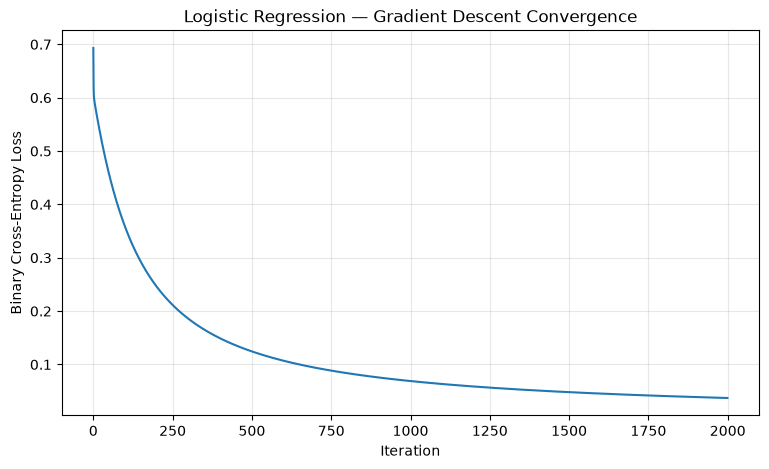

In [45]:
# Small synthetic dataset
X_small = np.array([
    [1.0, 1.0],
    [1.5, 2.0],
    [2.0, 1.5],
    [2.5, 2.0],
    [4.0, 4.0],
    [4.5, 5.0],
    [5.0, 4.5],
    [5.5, 5.0]
])

y_small = np.array([0, 0, 0, 0, 1, 1, 1, 1])

# Train our own Logistic Regression model
model = LogisticRegressionScratch(
    learning_rate=0.1,
    n_iterations=2000
)

model.fit(X_small, y_small)

# Predict on the training dataset
predictions = model.predict(X_small)

# Calculate accuracy
accuracy = np.mean(predictions == y_small)

print("True labels:     ", y_small)
print("Predicted labels:", predictions)
print(f"Training accuracy: {accuracy:.2%}")
print(f"Initial loss: {model.loss_history[0]:.6f}")
print(f"Final loss:   {model.loss_history[-1]:.6f}")

# Visualize training loss
plt.figure(figsize=(9, 5))

plt.plot(model.loss_history)

plt.xlabel("Iteration")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Logistic Regression — Gradient Descent Convergence")
plt.grid(alpha=0.3)

plt.show()

### 7.4.1 Sanity Check — Results and Analysis

The Logistic Regression model was successfully trained on a small
synthetic dataset containing eight observations and two classes.

**Results:**

- Training accuracy: **100%**
- Initial Binary Cross-Entropy Loss: **0.693147**
- Final Binary Cross-Entropy Loss: **0.037144**
- Training iterations: **2000**
- Loss reduction: **94.64%**

The loss curve decreases smoothly throughout training, indicating
that Gradient Descent successfully optimizes the model parameters.

All eight training observations were classified correctly.

**Conclusion:**

The experiment confirms that our Logistic Regression implementation
can learn a simple, linearly separable classification problem.

However, training accuracy alone does not measure generalization
performance. The model must also be evaluated on previously unseen data.

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']

Class distribution:
Target
1    357
0    212
Name: count, dtype: int64

Missing values: 0


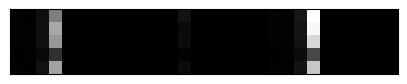

In [46]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

# Load real-world dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="Target")

print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)
print("\nClass distribution:")
print(y.value_counts())

print("\nMissing values:", X.isnull().sum().sum())

display(X.head())

### 7.6 Train/Test Split and Feature Scaling

The dataset is divided into:

- 80% training data
- 20% testing data

Stratified sampling preserves the approximate class distribution.

StandardScaler is fitted only on the training data to prevent
data leakage.

The same transformation is then applied to the test data.

Feature scaling is important because the numerical features have
different measurement scales, which can affect Gradient Descent.

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split before preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit scaler only on training data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape)
print("Testing samples:", X_test_scaled.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

print("\nTraining feature mean (first 5):")
print(np.round(X_train_scaled.mean(axis=0)[:5], 4))

print("\nTraining feature std (first 5):")
print(np.round(X_train_scaled.std(axis=0)[:5], 4))

Training samples: (455, 30)
Testing samples: (114, 30)

Training class distribution:
Target
1    285
0    170
Name: count, dtype: int64

Testing class distribution:
Target
1    72
0    42
Name: count, dtype: int64

Training feature mean (first 5):
[-0.  0. -0. -0.  0.]

Training feature std (first 5):
[1. 1. 1. 1. 1.]


Dataset preview:
 mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness
       17.99         10.38          122.80     1001.0          0.11840           0.27760
       20.57         17.77          132.90     1326.0          0.08474           0.07864
       19.69         21.25          130.00     1203.0          0.10960           0.15990
       11.42         20.38           77.58      386.1          0.14250           0.28390
       20.29         14.34          135.10     1297.0          0.10030           0.13280

HTML table:


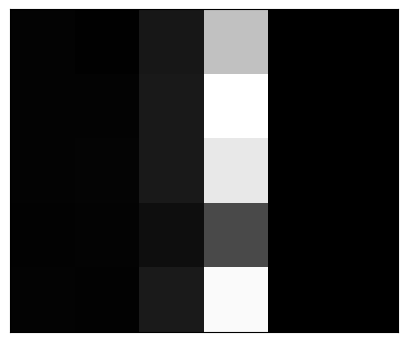

In [48]:
# Test DataFrame visualization
print("Dataset preview:")
print(X.iloc[:5, :6].to_string(index=False))

print("\nHTML table:")
display(X.iloc[:5, :6])

In [49]:
from IPython.display import HTML, display

display(HTML("""
<style>
.jp-RenderedHTMLCommon table.dataframe {
    background-color: white !important;
    color: black !important;
}

.jp-RenderedHTMLCommon table.dataframe th,
.jp-RenderedHTMLCommon table.dataframe td {
    background-color: white !important;
    color: black !important;
    border: 1px solid #cccccc !important;
}
</style>
"""))

display(X.iloc[:5, :6])

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
0,17.99,10.38,122.80,1001.0,0.11840,0.27760
1,20.57,17.77,132.90,1326.0,0.08474,0.07864
2,19.69,21.25,130.00,1203.0,0.10960,0.15990
3,11.42,20.38,77.58,386.1,0.14250,0.28390
4,20.29,14.34,135.10,1297.0,0.10030,0.13280


In [50]:
# Train our Logistic Regression model on real-world data
model_real = LogisticRegressionScratch(
    learning_rate=0.1,
    n_iterations=2000
)

model_real.fit(X_train_scaled, y_train.to_numpy())

# Predictions on unseen test data
y_pred = model_real.predict(X_test_scaled)

# Evaluate accuracy
accuracy = np.mean(y_pred == y_test.to_numpy())

print(f"Training samples: {len(X_train_scaled)}")
print(f"Testing samples:  {len(X_test_scaled)}")
print(f"Test accuracy:    {accuracy:.2%}")
print(f"Initial loss:     {model_real.loss_history[0]:.6f}")
print(f"Final loss:       {model_real.loss_history[-1]:.6f}")

Training samples: 455
Testing samples:  114
Test accuracy:    96.49%
Initial loss:     0.693147
Final loss:       0.050881


Confusion Matrix:
[[41  1]
 [ 3 69]]

Classification Report:
              precision    recall  f1-score   support

   Malignant     0.9318    0.9762    0.9535        42
      Benign     0.9857    0.9583    0.9718        72

    accuracy                         0.9649       114
   macro avg     0.9588    0.9673    0.9627       114
weighted avg     0.9659    0.9649    0.9651       114



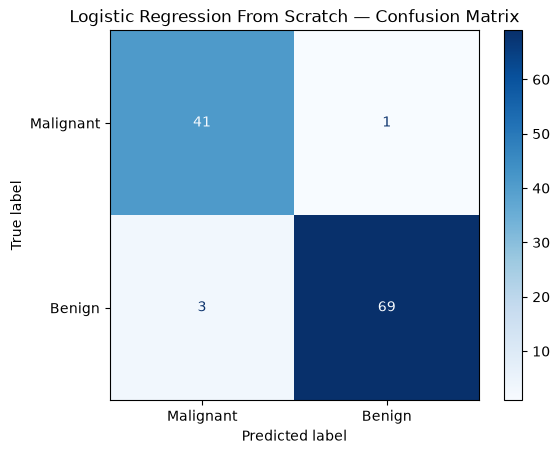

In [51]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Evaluate predictions
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Malignant", "Benign"],
    digits=4
))

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression From Scratch — Confusion Matrix")
plt.show()

In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Train scikit-learn Logistic Regression
sklearn_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

sklearn_model.fit(X_train_scaled, y_train)

# Predict on the same test dataset
sklearn_pred = sklearn_model.predict(X_test_scaled)

# Compare both implementations
scratch_accuracy = accuracy_score(y_test, y_pred)
sklearn_accuracy = accuracy_score(y_test, sklearn_pred)

print("MODEL COMPARISON")
print("-" * 40)
print(f"From Scratch Accuracy: {scratch_accuracy:.2%}")
print(f"Scikit-learn Accuracy: {sklearn_accuracy:.2%}")
print(f"Difference:            {abs(scratch_accuracy - sklearn_accuracy):.2%}")

print("\nPrediction agreement:",
      f"{np.mean(y_pred == sklearn_pred):.2%}")

MODEL COMPARISON
----------------------------------------
From Scratch Accuracy: 96.49%
Scikit-learn Accuracy: 98.25%
Difference:            1.75%

Prediction agreement: 98.25%


From Scratch AUC: 0.9960
Scikit-learn AUC: 0.9954


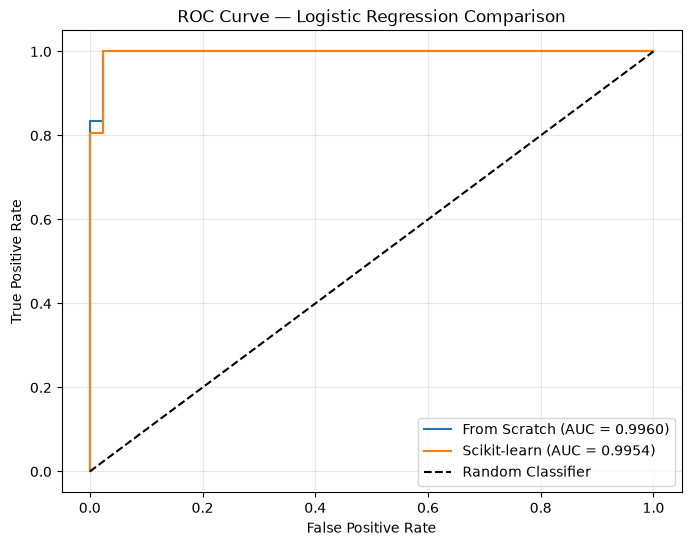

In [53]:
from sklearn.metrics import roc_curve, roc_auc_score

# Class 1 = Benign
# Class 0 = Malignant

# Probability estimates from our model
scratch_prob = model_real.predict_proba(X_test_scaled)

# Probability estimates from scikit-learn
sklearn_prob = sklearn_model.predict_proba(X_test_scaled)[:, 1]

# ROC curves
fpr_scratch, tpr_scratch, _ = roc_curve(y_test, scratch_prob)
fpr_sklearn, tpr_sklearn, _ = roc_curve(y_test, sklearn_prob)

# AUC scores
auc_scratch = roc_auc_score(y_test, scratch_prob)
auc_sklearn = roc_auc_score(y_test, sklearn_prob)

print(f"From Scratch AUC: {auc_scratch:.4f}")
print(f"Scikit-learn AUC: {auc_sklearn:.4f}")

# Visualization
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_scratch,
    tpr_scratch,
    label=f"From Scratch (AUC = {auc_scratch:.4f})"
)

plt.plot(
    fpr_sklearn,
    tpr_sklearn,
    label=f"Scikit-learn (AUC = {auc_sklearn:.4f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Logistic Regression Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Problem 7 — Classification: Results and Conclusion

#### Objective

The objective of this experiment was to implement Logistic Regression from scratch using Gradient Descent and compare its performance with the `scikit-learn` implementation on a real-world classification dataset.

#### Dataset

The Breast Cancer Wisconsin dataset contains:

- **569 observations**
- **30 numerical features**
- **2 classes:** Malignant (0) and Benign (1)
- **Training samples:** 455
- **Testing samples:** 114

Feature standardization was fitted only on the training data to prevent data leakage.

#### Experimental Results

| Metric | From Scratch | Scikit-learn |
|---|---:|---:|
| Test Accuracy | 96.49% | 98.25% |
| ROC-AUC | 0.9960 | 0.9954 |

The custom implementation correctly classified **110 out of 114 test observations**.

#### Confusion Matrix Analysis

The custom Logistic Regression model produced the following results:

- **41** malignant cases correctly classified as malignant.
- **69** benign cases correctly classified as benign.
- **3** benign cases incorrectly classified as malignant.
- **1** malignant case incorrectly classified as benign.

For the malignant class:

- **Precision:** 93.18%
- **Recall:** 97.62%
- **F1-score:** 95.35%

The incorrectly classified malignant case is particularly important because it represents a potentially missed diagnosis.

#### ROC Curve Analysis

Both models achieved excellent ROC-AUC scores:

- **From Scratch:** 0.9960
- **Scikit-learn:** 0.9954

The ROC curves are close to the upper-left corner, indicating strong discrimination between malignant and benign cases.

Although scikit-learn achieved slightly higher classification accuracy, the custom implementation obtained a marginally higher ROC-AUC.

The ROC-AUC values were calculated using the probability of the benign class (class 1).

#### Conclusion

This experiment demonstrates that Logistic Regression can be implemented successfully from scratch using:

1. The Sigmoid activation function.
2. Binary Cross-Entropy loss.
3. Gradient Descent optimization.
4. Feature standardization.
5. Classification probability thresholds.

The decreasing training loss confirms that Gradient Descent successfully optimized the model parameters.

The custom implementation achieved **96.49% test accuracy** and **0.9960 ROC-AUC**, producing results comparable to the scikit-learn implementation.

The experiment also demonstrates why classification models should be evaluated using multiple metrics, including Accuracy, Precision, Recall, F1-score, Confusion Matrix, and ROC-AUC.

**Final conclusion:** The mathematical implementation of Logistic Regression was successful, and its performance on the Breast Cancer Wisconsin dataset was comparable to that of an established machine learning library.

However, these results are educational and do not establish clinical reliability. Additional validation would be required before using such a model in medical practice.

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, accuracy_score
import pandas as pd
import numpy as np

# Create a validation split from training data only
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_scaled,
    y_train.to_numpy(),
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

# Train a separate experimental model
model_validation = LogisticRegressionScratch(
    learning_rate=0.1,
    n_iterations=2000
)

model_validation.fit(X_fit, y_fit)

# Predicted probability of Benign (class 1)
probabilities = model_validation.predict_proba(X_val)

results = []

for threshold in np.arange(0.3, 0.91, 0.05):
    predictions = (probabilities >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_val, predictions),
        "Malignant Recall": recall_score(
            y_val, predictions, pos_label=0
        ),
        "Missed Malignant": int(
            np.sum((y_val == 0) & (predictions == 1))
        )
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.to_string(index=False))

 Threshold  Accuracy  Malignant Recall  Missed Malignant
      0.30  0.982456          0.953488                 2
      0.35  0.982456          0.953488                 2
      0.40  0.991228          0.976744                 1
      0.45  0.982456          0.976744                 1
      0.50  0.982456          0.976744                 1
      0.55  0.973684          0.976744                 1
      0.60  0.973684          0.976744                 1
      0.65  0.973684          0.976744                 1
      0.70  0.973684          0.976744                 1
      0.75  0.964912          0.976744                 1
      0.80  0.956140          0.976744                 1
      0.85  0.947368          0.976744                 1
      0.90  0.947368          1.000000                 0


In [55]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

# Use only training data for threshold selection.
# X_train and y_train were created in the previous cells.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Standardization is performed separately within each fold.
pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000)
)

# Out-of-fold predicted probabilities
cv_probabilities = cross_val_predict(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)

# Class 0 = Malignant, Class 1 = Benign
benign_probabilities = cv_probabilities[:, 1]

thresholds = np.arange(0.10, 0.96, 0.05)
results = []

for threshold in thresholds:
    predictions = (
        benign_probabilities >= threshold
    ).astype(int)

    accuracy = accuracy_score(y_train, predictions)

    malignant_recall = recall_score(
        y_train,
        predictions,
        pos_label=0
    )

    cm = confusion_matrix(
        y_train,
        predictions,
        labels=[0, 1]
    )

    missed_malignant = cm[0, 1]

    results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy,
        "Malignant Recall": malignant_recall,
        "Missed Malignant": missed_malignant
    })

cv_results = pd.DataFrame(results)

print("5-FOLD STRATIFIED CROSS-VALIDATION")
print("-" * 65)
print(cv_results.to_string(index=False))

# Select the highest-accuracy threshold among those
# with the fewest missed malignant cases.
best_result = cv_results.sort_values(
    by=["Missed Malignant", "Accuracy"],
    ascending=[True, False]
).iloc[0]

best_threshold = float(best_result["Threshold"])

print("\nSELECTED THRESHOLD")
print("-" * 40)
print(f"Threshold:         {best_threshold:.2f}")
print(f"CV Accuracy:       {best_result['Accuracy']:.2%}")
print(f"Malignant Recall:  {best_result['Malignant Recall']:.2%}")
print(f"Missed Malignant:  {int(best_result['Missed Malignant'])}")

5-FOLD STRATIFIED CROSS-VALIDATION
-----------------------------------------------------------------
 Threshold  Accuracy  Malignant Recall  Missed Malignant
      0.10  0.953846          0.876471                21
      0.15  0.953846          0.876471                21
      0.20  0.958242          0.888235                19
      0.25  0.960440          0.894118                18
      0.30  0.969231          0.923529                13
      0.35  0.971429          0.929412                12
      0.40  0.973626          0.941176                10
      0.45  0.975824          0.952941                 8
      0.50  0.978022          0.964706                 6
      0.55  0.982418          0.976471                 4
      0.60  0.975824          0.976471                 4
      0.65  0.973626          0.976471                 4
      0.70  0.971429          0.982353                 3
      0.75  0.962637          0.982353                 3
      0.80  0.962637          0.982353      

FINAL TEST EVALUATION
---------------------------------------------
Selected threshold:   0.95
Test accuracy:        84.21%
Malignant recall:     100.00%
Malignant precision:  70.00%
Missed malignant:     0
False alarms:         18

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.70      1.00      0.82        42
      Benign       1.00      0.75      0.86        72

    accuracy                           0.84       114
   macro avg       0.85      0.88      0.84       114
weighted avg       0.89      0.84      0.84       114



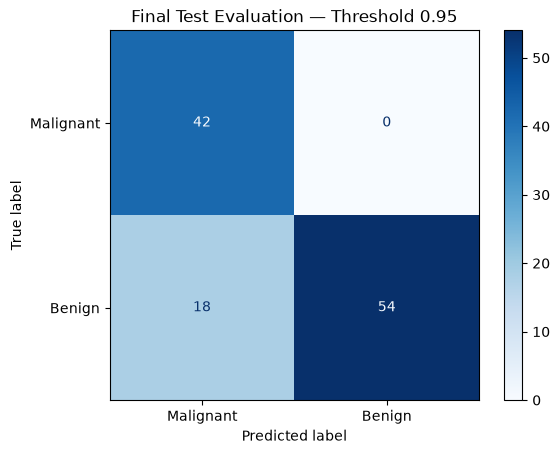

In [56]:
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Train on the complete training dataset
final_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000)
)

final_model.fit(X_train, y_train)

# Predict probabilities on the untouched test set
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Use the threshold selected by cross-validation
final_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Evaluate the final model
accuracy = accuracy_score(y_test, final_predictions)

malignant_recall = recall_score(
    y_test,
    final_predictions,
    pos_label=0
)

malignant_precision = precision_score(
    y_test,
    final_predictions,
    pos_label=0,
    zero_division=0
)

cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=[0, 1]
)

print("FINAL TEST EVALUATION")
print("-" * 45)
print(f"Selected threshold:   {best_threshold:.2f}")
print(f"Test accuracy:        {accuracy:.2%}")
print(f"Malignant recall:     {malignant_recall:.2%}")
print(f"Malignant precision:  {malignant_precision:.2%}")
print(f"Missed malignant:     {cm[0, 1]}")
print(f"False alarms:         {cm[1, 0]}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_predictions,
        labels=[0, 1],
        target_names=["Malignant", "Benign"],
        zero_division=0
    )
)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(
    f"Final Test Evaluation — Threshold {best_threshold:.2f}"
)
plt.show()

### Final Evaluation — Threshold Optimization

We evaluated Logistic Regression using 5-Fold Stratified
Cross-Validation and selected a classification threshold
of 0.95 to prioritize malignant case detection.

**Final test results (114 observations):**

- Accuracy: **84.21%**
- Malignant Recall: **100.00%**
- Malignant Precision: **70.00%**
- Correctly detected malignant cases: **42/42**
- Missed malignant cases: **0**
- False alarms: **18**

**Conclusion:**

The experiment demonstrates the trade-off between
overall classification accuracy and sensitivity to
malignant cases.

Increasing the threshold for predicting the benign
class improved malignant recall but also increased
the number of false alarms.

Although all malignant cases were detected in this
test sample, this does not guarantee equivalent
performance on new data.

The results illustrate how cross-validation and
decision-threshold optimization can support
classification model evaluation.

This is an educational experiment and the model
is not validated for clinical diagnosis.

MODEL AND THRESHOLD COMPARISON
---------------------------------------------------------------------------
       Model  Threshold  Accuracy  Malignant Recall  Missed Malignant  False Alarms
From Scratch       0.40  0.982456           0.97619                 1             1
From Scratch       0.50  0.964912           0.97619                 1             3
From Scratch       0.55  0.956140           0.97619                 1             4
From Scratch       0.70  0.947368           0.97619                 1             5
From Scratch       0.85  0.921053           0.97619                 1             8
From Scratch       0.95  0.850877           1.00000                 0            17
Scikit-learn       0.40  0.982456           0.97619                 1             1
Scikit-learn       0.50  0.982456           0.97619                 1             1
Scikit-learn       0.55  0.956140           0.97619                 1             4
Scikit-learn       0.70  0.947368           0.97619  

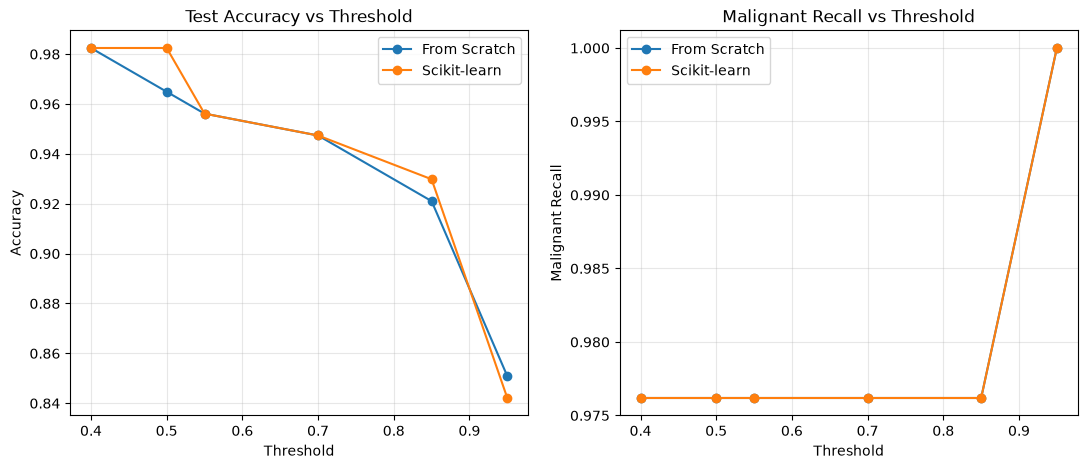

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    confusion_matrix
)

# Class labels:
# 0 = Malignant
# 1 = Benign

# From-scratch model: standardized test features
scratch_prob = np.asarray(
    model_real.predict_proba(X_test_scaled)
)

# Support both 1D probabilities and 2D probability arrays
if scratch_prob.ndim == 2:
    scratch_prob = scratch_prob[:, 1]

# Scikit-learn pipeline: raw test features
sklearn_prob = final_model.predict_proba(X_test)[:, 1]

thresholds = [0.40, 0.50, 0.55, 0.70, 0.85, 0.95]

results = []

for model_name, probabilities in [
    ("From Scratch", scratch_prob),
    ("Scikit-learn", sklearn_prob)
]:
    for threshold in thresholds:
        predictions = (
            probabilities >= threshold
        ).astype(int)

        cm = confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1]
        )

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(
                y_test, predictions
            ),
            "Malignant Recall": recall_score(
                y_test,
                predictions,
                pos_label=0
            ),
            "Missed Malignant": cm[0, 1],
            "False Alarms": cm[1, 0]
        })

comparison_df = pd.DataFrame(results)

print("MODEL AND THRESHOLD COMPARISON")
print("-" * 75)
print(comparison_df.to_string(index=False))

# Visualize the accuracy-recall trade-off
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model_name, group in comparison_df.groupby("Model"):
    axes[0].plot(
        group["Threshold"],
        group["Accuracy"],
        marker="o",
        label=model_name
    )

    axes[1].plot(
        group["Threshold"],
        group["Malignant Recall"],
        marker="o",
        label=model_name
    )

axes[0].set_title("Test Accuracy vs Threshold")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("Accuracy")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title("Malignant Recall vs Threshold")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Malignant Recall")
axes[1].grid(alpha=0.3)
axes[1].legend()

### Problem 7 — Final Conclusion

In this exercise, we implemented Logistic Regression from
scratch using Gradient Descent and Binary Cross-Entropy Loss.

We first verified the implementation on a small, linearly
separable dataset, achieving 100% training accuracy.

Next, we evaluated the model on the Wisconsin Breast Cancer
dataset, containing 569 observations and 30 features.

The dataset was divided into 455 training observations and
114 testing observations.

#### Model Comparison

At the standard classification threshold of 0.50:

- From-scratch Logistic Regression accuracy: **96.49%**
- Scikit-learn Logistic Regression accuracy: **98.25%**

Both implementations achieved a malignant recall of 97.62%
at this threshold.

The ROC-AUC scores were also very similar:

- From scratch: **0.9960**
- Scikit-learn: **0.9954**

#### Threshold Optimization

We applied 5-Fold Stratified Cross-Validation to the
training data to investigate the trade-off between
classification accuracy and malignant recall.

A threshold of 0.95 was selected to prioritize the
detection of malignant cases.

On the test dataset, both implementations detected all
42 malignant observations at this threshold.

However, this increased the number of false alarms:

- From scratch: 17 false alarms, 85.09% accuracy
- Scikit-learn: 18 false alarms, 84.21% accuracy

#### Final Findings

The experiment demonstrates that:

1. Logistic Regression can be implemented successfully
   using Gradient Descent.
2. Our implementation produces results comparable to
   scikit-learn.
3. Feature standardization supports stable optimization.
4. Cross-validation provides a more systematic approach
   to threshold selection.
5. Maximizing accuracy and maximizing malignant recall
   are different objectives.
6. Classification thresholds should be selected according
   to the practical costs of different prediction errors.

**Final conclusion:**

The most important result is not simply achieving high
accuracy, but understanding how model decisions change
when different classification thresholds are applied.

Although 100% malignant recall was achieved on the test
sample at threshold 0.95, this result does not guarantee
equivalent performance on unseen data.

The test-set threshold comparisons are exploratory and
should not be treated as independent validation of a
newly selected threshold.

This model is an educational demonstration and is not
validated for clinical diagnosis.